# ERA5 Geopotential Height — Convolutional Autoencoder vs Baselines

**Dataset:** ERA5 reanalysis — 500 hPa geopotential height (z500) over the North Atlantic/Europe  
**Model:** Convolutional Autoencoder (PyTorch) — **trained from scratch** on this data  
**Baselines:** Climatological mean · PCA reconstruction  
**Task:** Learn a compressed spatial representation of synoptic weather patterns; evaluate reconstruction quality.

---
## 0. Setup & Installation

In [ ]:
# Install dependencies
!pip install cdsapi xarray netCDF4 cartopy torch torchvision scikit-learn matplotlib numpy tqdm --quiet

In [ ]:
import os, json, warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from sklearn.decomposition import PCA
from sklearn.metrics import mean_squared_error, mean_absolute_error
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split

# Prevent warning spam, set seeds for reproducability
warnings.filterwarnings('ignore')
torch.manual_seed(42)
np.random.seed(42)

# CHeck that NVidia GPU is used
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {DEVICE}')

Using device: cuda


---
## 1. Download ERA5 Data via CDS API

**Before running this section:**
1. Register at https://cds.climate.copernicus.eu/
2. Accept the ERA5 licence
3. Find your UID and API key at https://cds.climate.copernicus.eu/profile
4. Create the file `~/.cdsapirc` with:
```
url: https://cds.climate.copernicus.eu/api/v2
key: <UID>:<API-KEY>
```

We use the **ERA5 monthly means** dataset (`reanalysis-era5-pressure-levels-monthly-means`).  
This avoids the CDS per-request size limit that daily data triggers (~16,000 fields vs ~530).  
For an autoencoder learning large-scale circulation patterns, monthly resolution is perfectly appropriate — synoptic regimes (blocking, zonal flow, NAO) are well-represented at this timescale.

**Data:** 500 hPa geopotential height, 1979–2022, 2.5° grid, North Atlantic/Europe (~530 time steps)

In [ ]:
import cdsapi

DATA_PATH = 'era5_z500_monthly.nc'

if not os.path.exists(DATA_PATH):
    c = cdsapi.Client()
    c.retrieve(
        'reanalysis-era5-pressure-levels-monthly-means',   # ← monthly means, no size limit issues
        {
            'product_type': 'monthly_averaged_reanalysis',
            'variable': 'geopotential',
            'pressure_level': '500',
            'year': [str(y) for y in range(1979, 2023)],
            'month': [f'{m:02d}' for m in range(1, 13)],
            'time': '00:00',           # required field for monthly means
            'area': [80, -60, 20, 40], # N, W, S, E — North Atlantic / Europe
            'grid': [2.5, 2.5],
            'format': 'netcdf',
        },
        DATA_PATH
    )
    print('Download complete.')
else:
    print(f'Using cached file: {DATA_PATH}')

Using cached file: era5_z500_monthly.nc


---
## 2. Load & Explore the Data

In [ ]:
ds = xr.open_dataset(DATA_PATH)
print(ds)  # inspect and check the coordinate names

G = 9.80665  # m s⁻²

# Extract z500 data
# Newer CDS API adds extra dimensions (pressure_level, number, expver).
# squeeze() drops any dimension of size 1 so we end up with (time, lat, lon).
z_da = (ds['z'] / G).squeeze()

# The time coordinate is 'valid_time' in newer CDS output, 'time' in older.
time_coord = 'valid_time' if 'valid_time' in z_da.coords else 'time'
z_da = z_da.sortby(time_coord)   # ensure chronological order

lats  = ds['latitude'].values
lons  = ds['longitude'].values
times = z_da[time_coord].values
z500  = z_da.values               # shape: (T, lat, lon)

# Sanity checks
assert z500.ndim == 3, f"Expected 3-D array, got shape {z500.shape}. Remaining dims: {z_da.dims}"
N, H, W = z500.shape

print(f'\nGeopotential height array shape: {z500.shape}')
print(f'Time coordinate used: "{time_coord}"')
print(f'Lat range: {lats.min():.1f} → {lats.max():.1f}')
print(f'Lon range: {lons.min():.1f} → {lons.max():.1f}')
print(f'Time steps: {N}  ({str(times[0])[:10]} → {str(times[-1])[:10]})')
print(f'z500 range: {z500.min():.0f} – {z500.max():.0f} m')

<xarray.Dataset> Size: 2MB
Dimensions:         (valid_time: 528, pressure_level: 1, latitude: 25,
                     longitude: 41)
Coordinates:
  * valid_time      (valid_time) datetime64[ns] 4kB 1979-01-01 ... 2022-12-01
    expver          (valid_time) <U4 8kB ...
  * pressure_level  (pressure_level) float64 8B 500.0
  * latitude        (latitude) float64 200B 80.0 77.5 75.0 ... 25.0 22.5 20.0
  * longitude       (longitude) float64 328B -60.0 -57.5 -55.0 ... 37.5 40.0
    number          int64 8B ...
Data variables:
    z               (valid_time, pressure_level, latitude, longitude) float32 2MB ...
Attributes:
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-18T12:13 GRIB to CDM+CF via cfgrib-0.9.1...

Geopotential height array shape

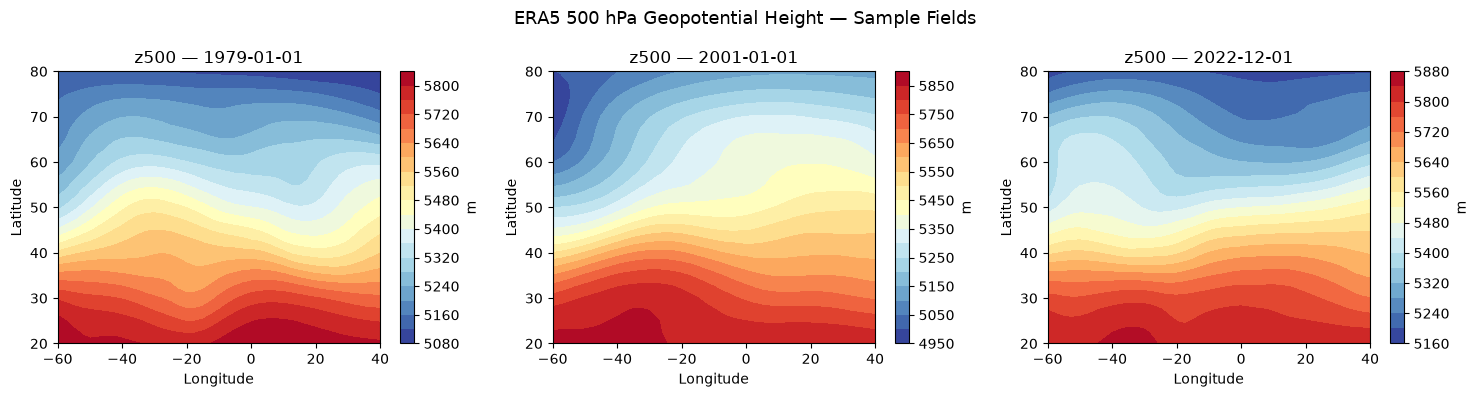

In [7]:
# Quick look at a sample field
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sample_indices = [0, len(times)//2, -1]
for ax, idx in zip(axes, sample_indices):
    im = ax.contourf(lons, lats, z500[idx], levels=20, cmap='RdYlBu_r')
    ax.set_title(f'z500 — {str(times[idx])[:10]}')
    ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
    plt.colorbar(im, ax=ax, label='m')
plt.suptitle('ERA5 500 hPa Geopotential Height — Sample Fields', fontsize=13)
plt.tight_layout()
plt.savefig('sample_fields.png', dpi=100)
plt.show()

---
## 3. Preprocessing

In [ ]:
# Normalise to zero mean, unit variance (per-pixel climatology)
clim_mean = z500.mean(axis=0)          # shape: (lat, lon)
clim_std  = z500.std(axis=0)
clim_std  = np.where(clim_std < 1e-6, 1.0, clim_std)   # avoid div-by-zero

z500_norm = (z500 - clim_mean) / clim_std  # shape: (T, lat, lon)

N, H, W = z500_norm.shape
print(f'Normalised array: shape={z500_norm.shape}, mean≈{z500_norm.mean():.4f}, std≈{z500_norm.std():.4f}')

# Chronological train / val / test split
n_train = int(0.70 * N)   # ~1979–2009
n_val   = int(0.15 * N)   # ~2010–2015
n_test  = N - n_train - n_val

z_train = z500_norm[:n_train]
z_val   = z500_norm[n_train:n_train + n_val]
z_test  = z500_norm[n_train + n_val:]

print(f'Train: {n_train}  Val: {n_val}  Test: {n_test} samples')

Normalised array: shape=(528, 25, 41), mean≈-0.0000, std≈1.0000
Train: 369  Val: 79  Test: 80 samples


In [ ]:
# PyTorch Dataset 
class WeatherFieldDataset(Dataset):
    """Each sample is one 2-D geopotential height field (H × W).
    Adds a channel dimension so shape is (1, H, W) for Conv2d."""

    def __init__(self, data: np.ndarray):
        # data shape: (N, H, W) → tensor (N, 1, H, W)
        self.data = torch.from_numpy(data).float().unsqueeze(1)

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        return self.data[idx]


BATCH_SIZE = 64

train_ds = WeatherFieldDataset(z_train)
val_ds   = WeatherFieldDataset(z_val)
test_ds  = WeatherFieldDataset(z_test)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f'Sample batch shape: {next(iter(train_loader)).shape}')  # → (64, 1, H, W)

Sample batch shape: torch.Size([64, 1, 25, 41])


---
## 4. Convolutional Autoencoder

Architecture overview:
```
Input (1, H, W)
  │
  ├─ Encoder: Conv2d → BN → ReLU → MaxPool  (×3)
  │           → Flatten → Linear
  │
  └─ Bottleneck (LATENT_DIM)  ← compressed representation
  │
  ├─ Decoder: Linear → Reshape → ConvTranspose2d → BN → ReLU  (×3)
  │           → ConvTranspose2d (no activation)
  │
Output (1, H, W)  — reconstructed field
```

The latent space dimension controls the compression ratio. We explore `LATENT_DIM ∈ {16, 32, 64}`.

In [ ]:
class ConvEncoder(nn.Module):
    def __init__(self, in_h: int, in_w: int, latent_dim: int):
        super().__init__()
        # Three convolutional blocks — each halves spatial dims
        self.conv_blocks = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 16, kernel_size=3, padding=1),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),   # H/2, W/2

            # Block 2
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),   # H/4, W/4

            # Block 3
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),   # H/8, W/8
        )
        # Compute flattened size after pooling
        self.flat_h = in_h // 8
        self.flat_w = in_w // 8
        self.flat_dim = 64 * self.flat_h * self.flat_w

        self.fc = nn.Linear(self.flat_dim, latent_dim)

    def forward(self, x):
        x = self.conv_blocks(x)
        x = x.view(x.size(0), -1)  # flatten
        return self.fc(x)


class ConvDecoder(nn.Module):
    def __init__(self, flat_h: int, flat_w: int, latent_dim: int):
        super().__init__()
        self.flat_h = flat_h
        self.flat_w = flat_w
        self.flat_dim = 64 * flat_h * flat_w

        self.fc = nn.Linear(latent_dim, self.flat_dim)

        self.deconv_blocks = nn.Sequential(
            # Block 1
            nn.ConvTranspose2d(64, 32, kernel_size=2, stride=2),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            # Block 2
            nn.ConvTranspose2d(32, 16, kernel_size=2, stride=2),
            nn.BatchNorm2d(16),
            nn.ReLU(),

            # Block 3 — output layer, no activation
            nn.ConvTranspose2d(16, 1, kernel_size=2, stride=2),
        )

    def forward(self, z):
        x = self.fc(z)
        x = x.view(x.size(0), 64, self.flat_h, self.flat_w)
        return self.deconv_blocks(x)


class ConvAutoencoder(nn.Module):
    def __init__(self, in_h: int, in_w: int, latent_dim: int = 32):
        super().__init__()
        self.encoder = ConvEncoder(in_h, in_w, latent_dim)
        self.decoder = ConvDecoder(
            self.encoder.flat_h, self.encoder.flat_w, latent_dim
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

    def encode(self, x):
        return self.encoder(x)


# Sanity check 
LATENT_DIM = 32
model = ConvAutoencoder(H, W, latent_dim=LATENT_DIM).to(DEVICE)

dummy = torch.zeros(2, 1, H, W).to(DEVICE)
out   = model(dummy)
print(f'Input shape:      {dummy.shape}')
print(f'Latent dim:       {LATENT_DIM}')
print(f'Output shape:     {out.shape}')
print(f'Compression ratio: {H*W / LATENT_DIM:.1f}×')

total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters: {total_params:,}')

Input shape:      torch.Size([2, 1, 25, 41])
Latent dim:       32
Output shape:     torch.Size([2, 1, 24, 40])
Compression ratio: 32.0×
Total parameters: 96,401


---
## 5. Training

Epoch   1/60  train=1.04855  val=0.98430
Epoch   5/60  train=0.26931  val=0.29360
Epoch  10/60  train=0.11937  val=0.14659
Epoch  15/60  train=0.07384  val=0.09562
Epoch  20/60  train=0.06530  val=0.06949
Epoch  25/60  train=0.05077  val=0.05045
Epoch  30/60  train=0.03972  val=0.04574
Epoch  35/60  train=0.03501  val=0.04585
Epoch  40/60  train=0.03540  val=0.03313
Epoch  45/60  train=0.02667  val=0.02941
Epoch  50/60  train=0.02660  val=0.02829
Epoch  55/60  train=0.03100  val=0.02643
Epoch  60/60  train=0.02263  val=0.02500


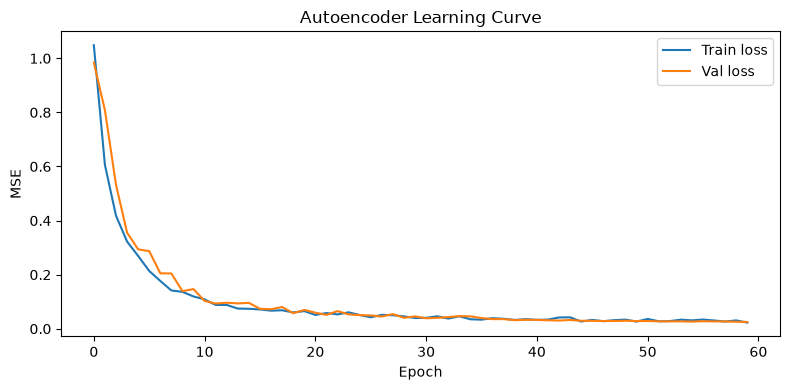

In [ ]:
def train_autoencoder(
    model, train_loader, val_loader,
    n_epochs=50, lr=1e-3, patience=8
):
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, patience=4, factor=0.5)
    criterion = nn.MSELoss()

    history = {'train_loss': [], 'val_loss': []}
    best_val  = float('inf')
    wait      = 0

    for epoch in range(1, n_epochs + 1):
        # Train
        model.train()
        train_loss = 0.0
        for batch in train_loader:
            batch = batch.to(DEVICE)
            optimizer.zero_grad()
            recon = model(batch)
            # Crop recon if needed (padding artefacts can change spatial size slightly)
            recon = torch.nn.functional.interpolate(recon, size=(batch.shape[-2], batch.shape[-1]), mode='bilinear', align_corners=False)
            loss = criterion(recon, batch)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * batch.size(0)
        train_loss /= len(train_loader.dataset)

        # Validate
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for batch in val_loader:
                batch = batch.to(DEVICE)
                recon = model(batch)
                recon = torch.nn.functional.interpolate(recon, size=(batch.shape[-2], batch.shape[-1]), mode='bilinear', align_corners=False)
                val_loss += criterion(recon, batch).item() * batch.size(0)
        val_loss /= len(val_loader.dataset)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        scheduler.step(val_loss)

        if val_loss < best_val:
            best_val = val_loss
            torch.save(model.state_dict(), 'best_autoencoder.pt')
            wait = 0
        else:
            wait += 1

        if epoch % 5 == 0 or epoch == 1:
            print(f'Epoch {epoch:3d}/{n_epochs}  '
                  f'train={train_loss:.5f}  val={val_loss:.5f}')

        if wait >= patience:
            print(f'Early stopping at epoch {epoch}.')
            break

    # Load best weights
    model.load_state_dict(torch.load('best_autoencoder.pt', map_location=DEVICE))
    return history


history = train_autoencoder(model, train_loader, val_loader, n_epochs=60)

# Plot learning curve
plt.figure(figsize=(8, 4))
plt.plot(history['train_loss'], label='Train loss')
plt.plot(history['val_loss'],   label='Val loss')
plt.xlabel('Epoch'); plt.ylabel('MSE')
plt.title('Autoencoder Learning Curve')
plt.legend(); plt.tight_layout()
plt.savefig('learning_curve.png', dpi=100)
plt.show()

---
## 6. Baselines

### 6a. Climatological Mean
The simplest possible "prediction" for any test field: just output the training-set mean at every grid point. No compression, no model — just the long-run average pattern. This sets the floor: any reasonable method must beat it convincingly.

In normalised units the training mean is close to zero everywhere (since we subtracted the all-data mean during normalisation), so this baseline is approximately predicting 0 at every pixel. Its RMSE will be close to 1.0 by construction, which gives a nice anchor: an RMSE of 0.3 means the model explains ~70% of the variability vs climatology.

### 6b. PCA Reconstruction
PCA is the optimal *linear* compression method. We fit it on the flattened training fields and reconstruct using the same number of components as our latent dimension. If the ConvAE beats PCA, the gain comes purely from nonlinearity.

Training climatological mean — shape: (25, 41)
  pixel mean: -0.0371  (≈0 in normalised space)
  pixel std:  0.0218

PCA with 32 components explains 99.8% of variance.


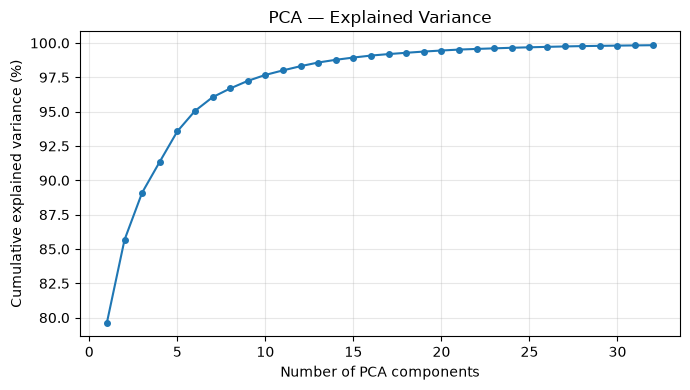

In [ ]:
# Climatological Mean Baseline
# Compute the mean field from the TRAINING set only (fair — no test data leakage)
train_clim_mean = z_train.mean(axis=0)   # shape: (H, W)

# Predict the same mean field for every test sample
z_test_clim_recon = np.broadcast_to(train_clim_mean, z_test.shape).copy()

print(f'Training climatological mean — shape: {train_clim_mean.shape}')
print(f'  pixel mean: {train_clim_mean.mean():.4f}  (≈0 in normalised space)')
print(f'  pixel std:  {train_clim_mean.std():.4f}')

# PCA Baseline
z_train_flat = z_train.reshape(n_train, -1)
z_test_flat  = z_test.reshape(n_test,  -1)

pca = PCA(n_components=LATENT_DIM)
pca.fit(z_train_flat)

explained = pca.explained_variance_ratio_.cumsum()
print(f'\nPCA with {LATENT_DIM} components explains {100*explained[-1]:.1f}% of variance.')

# Plot explained variance
plt.figure(figsize=(7, 4))
plt.plot(np.arange(1, LATENT_DIM+1), 100*pca.explained_variance_ratio_.cumsum(), marker='o', ms=4)
plt.xlabel('Number of PCA components')
plt.ylabel('Cumulative explained variance (%)')
plt.title('PCA — Explained Variance')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('pca_variance.png', dpi=100)
plt.show()

# Reconstruct test set
z_test_pca_codes = pca.transform(z_test_flat)
z_test_pca_recon = pca.inverse_transform(z_test_pca_codes).reshape(n_test, H, W)

---
## 7. Autoencoder Reconstruction on Test Set

In [17]:
model.eval()
ae_recons = []

with torch.no_grad():
    for batch in test_loader:
        batch = batch.to(DEVICE)
        recon = model(batch)
        recon = torch.nn.functional.interpolate(recon, size=(H, W), mode='bilinear', align_corners=False)   # trim any size mismatch
        ae_recons.append(recon.cpu().numpy())

# Shape: (n_test, 1, H, W) → (n_test, H, W)
z_test_ae_recon = np.concatenate(ae_recons, axis=0)[:, 0, :, :]

---
## 8. Evaluation & Comparison

──────────────────────────────────────────────────────────────────────
Climatological mean             RMSE=1.01759  MAE=0.87080  Corr=-0.05360
PCA (32 components)             RMSE=0.04436  MAE=0.03419  Corr=0.99900
Conv-AE (latent=32)             RMSE=0.15571  MAE=0.12076  Corr=0.98762
──────────────────────────────────────────────────────────────────────
PCA (32 components): 95.6% RMSE reduction vs climatological mean
Conv-AE (latent=32): 84.7% RMSE reduction vs climatological mean


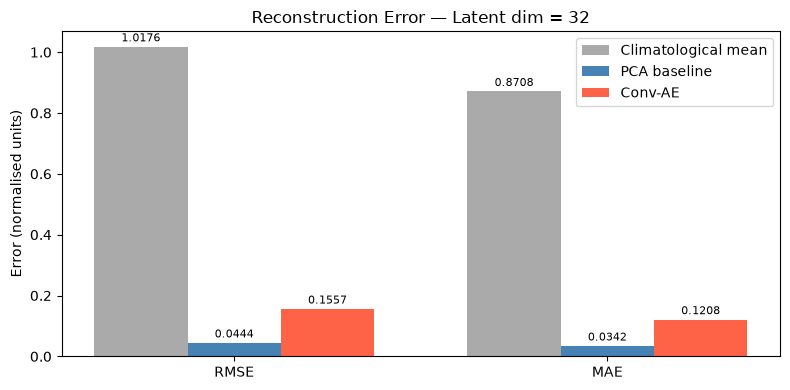

In [ ]:
def evaluate_recon(original, reconstructed, name='Model'):
    """Pixel-wise RMSE, MAE, and correlation on the normalised fields."""
    orig_flat  = original.reshape(-1)
    recon_flat = reconstructed.reshape(-1)
    mse  = mean_squared_error(orig_flat, recon_flat)
    mae  = mean_absolute_error(orig_flat, recon_flat)
    rmse = np.sqrt(mse)
    corr = np.corrcoef(orig_flat, recon_flat)[0, 1]
    print(f'{name:30s}  RMSE={rmse:.5f}  MAE={mae:.5f}  Corr={corr:.5f}')
    return {'name': name, 'RMSE': rmse, 'MAE': mae, 'Corr': corr}


print('─' * 70)
results_clim = evaluate_recon(z_test, z_test_clim_recon, name='Climatological mean')
results_pca  = evaluate_recon(z_test, z_test_pca_recon,  name=f'PCA ({LATENT_DIM} components)')
results_ae   = evaluate_recon(z_test, z_test_ae_recon,   name=f'Conv-AE (latent={LATENT_DIM})')
print('─' * 70)

# How much does each method reduce error vs climatology?
for r in [results_pca, results_ae]:
    reduction = 100 * (1 - r['RMSE'] / results_clim['RMSE'])
    print(f"{r['name']}: {reduction:.1f}% RMSE reduction vs climatological mean")

# Bar chart: all three methods
metrics = ['RMSE', 'MAE']
x = np.arange(len(metrics))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 4))
bars0 = ax.bar(x - width,   [results_clim[m] for m in metrics], width, label='Climatological mean', color='#aaaaaa')
bars1 = ax.bar(x,           [results_pca[m]  for m in metrics], width, label='PCA baseline',        color='steelblue')
bars2 = ax.bar(x + width,   [results_ae[m]   for m in metrics], width, label='Conv-AE',             color='tomato')

ax.set_xticks(x); ax.set_xticklabels(metrics)
ax.set_ylabel('Error (normalised units)')
ax.set_title(f'Reconstruction Error — Latent dim = {LATENT_DIM}')
ax.legend()
for bars in [bars0, bars1, bars2]:
    ax.bar_label(bars, fmt='%.4f', padding=2, fontsize=8)
plt.tight_layout()
plt.savefig('metric_comparison.png', dpi=100)
plt.show()

Epoch   1/40  train=1.15809  val=1.06714
Epoch   5/40  train=0.49576  val=0.53240
Epoch  10/40  train=0.34489  val=0.33102
Epoch  15/40  train=0.24494  val=0.25902
Epoch  20/40  train=0.17608  val=0.18063
Epoch  25/40  train=0.11907  val=0.11192
Epoch  30/40  train=0.08339  val=0.08554
Epoch  35/40  train=0.06781  val=0.06836
Epoch  40/40  train=0.05563  val=0.06033
Latent   8  Clim RMSE=1.01759  PCA RMSE=0.19433  AE RMSE=0.24460
Epoch   1/40  train=0.95528  val=0.99026
Epoch   5/40  train=0.39119  val=0.49695
Epoch  10/40  train=0.19644  val=0.21205
Epoch  15/40  train=0.13420  val=0.12592
Epoch  20/40  train=0.09150  val=0.09890
Epoch  25/40  train=0.08539  val=0.07311
Epoch  30/40  train=0.05827  val=0.07476
Epoch  35/40  train=0.05404  val=0.07224
Epoch  40/40  train=0.04586  val=0.04539
Latent  16  Clim RMSE=1.01759  PCA RMSE=0.10008  AE RMSE=0.21392
Epoch   1/40  train=0.94074  val=1.04106
Epoch   5/40  train=0.33994  val=0.40378
Epoch  10/40  train=0.15138  val=0.17034
Epoch  15

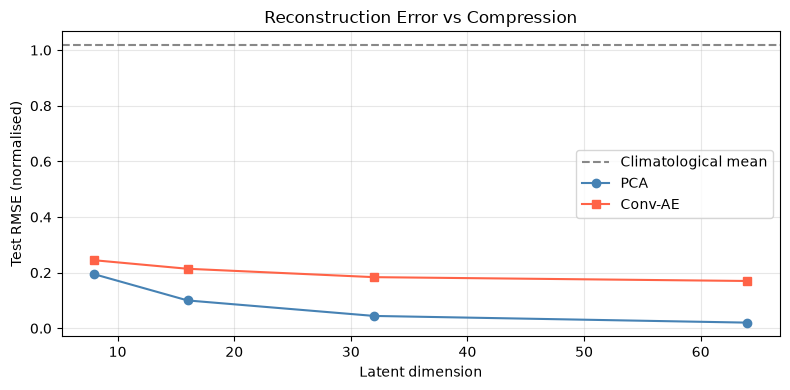

In [ ]:
# Vary latent dim and compare all three methods
# (Run once the single model is working — this takes a while)
LATENT_DIMS_TO_TRY = [8, 16, 32, 64]
comparison = []

# Climatological mean RMSE is constant (independent of latent dim)
rmse_clim = np.sqrt(mean_squared_error(z_test.flatten(), z_test_clim_recon.flatten()))

for ld in LATENT_DIMS_TO_TRY:
    # PCA
    pca_ld = PCA(n_components=ld).fit(z_train_flat)
    recon_pca = pca_ld.inverse_transform(pca_ld.transform(z_test_flat)).reshape(n_test, H, W)
    rmse_pca = np.sqrt(mean_squared_error(z_test.flatten(), recon_pca.flatten()))

    # AE — trained from scratch for this latent dim
    m_ld = ConvAutoencoder(H, W, latent_dim=ld).to(DEVICE)
    h_ld = train_autoencoder(m_ld, train_loader, val_loader, n_epochs=40, patience=6)
    m_ld.eval()
    recs = []
    with torch.no_grad():
        for batch in test_loader:
            r = torch.nn.functional.interpolate(m_ld(batch.to(DEVICE)), size=(H, W), mode='bilinear', align_corners=False).cpu().numpy()
            recs.append(r)
    recon_ae = np.concatenate(recs)[:, 0]
    rmse_ae  = np.sqrt(mean_squared_error(z_test.flatten(), recon_ae.flatten()))

    comparison.append({'latent_dim': ld, 'Clim_RMSE': rmse_clim,
                        'PCA_RMSE': rmse_pca, 'AE_RMSE': rmse_ae})
    print(f'Latent {ld:3d}  Clim RMSE={rmse_clim:.5f}  '
          f'PCA RMSE={rmse_pca:.5f}  AE RMSE={rmse_ae:.5f}')

# Plot
lds    = [r['latent_dim'] for r in comparison]
pca_rs = [r['PCA_RMSE']  for r in comparison]
ae_rs  = [r['AE_RMSE']   for r in comparison]

plt.figure(figsize=(8, 4))
plt.axhline(rmse_clim, color='#888888', linestyle='--', label='Climatological mean')
plt.plot(lds, pca_rs, 'o-', label='PCA',     color='steelblue')
plt.plot(lds, ae_rs,  's-', label='Conv-AE', color='tomato')
plt.xlabel('Latent dimension')
plt.ylabel('Test RMSE (normalised)')
plt.title('Reconstruction Error vs Compression')
plt.legend(); plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('rmse_vs_latent.png', dpi=100)
plt.show()

---
## 9. Visualise Reconstructions

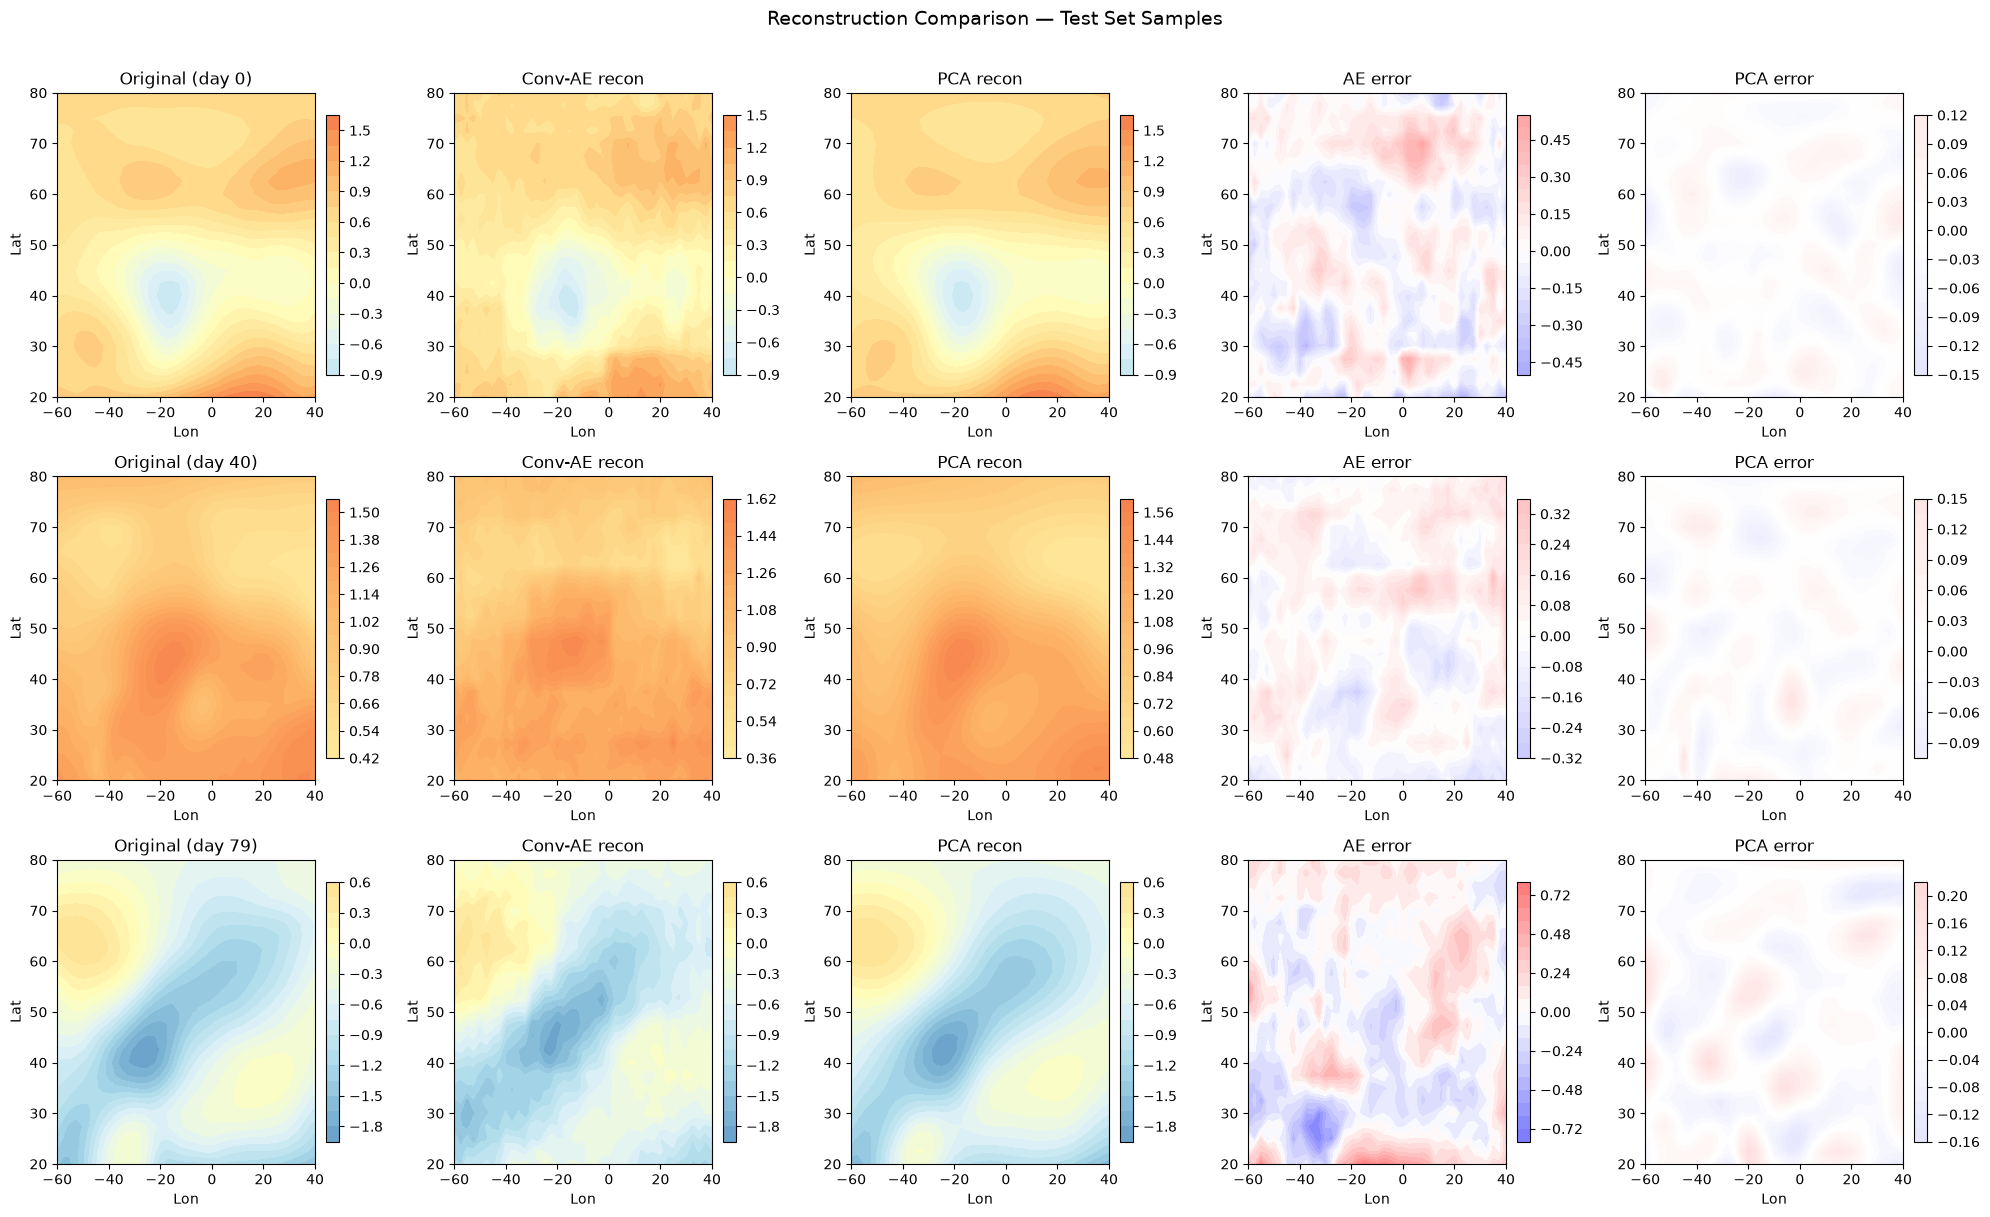

In [25]:
def plot_reconstructions(indices, original, ae_recon, pca_recon, lats, lons):
    """Side-by-side: original | AE recon | PCA recon | AE error | PCA error."""
    n = len(indices)
    fig, axes = plt.subplots(n, 5, figsize=(20, 4*n))
    if n == 1:
        axes = axes[np.newaxis, :]

    vmin, vmax = -3, 3   # normalised range
    emax = 1.5

    for row, idx in enumerate(indices):
        orig = original[idx]
        ae   = ae_recon[idx]
        pca  = pca_recon[idx]

        fields = [orig, ae, pca, ae - orig, pca - orig]
        titles = ['Original', 'Conv-AE recon', 'PCA recon', 'AE error', 'PCA error']
        cmaps  = ['RdYlBu_r', 'RdYlBu_r', 'RdYlBu_r', 'bwr', 'bwr']
        vmins  = [vmin, vmin, vmin, -emax, -emax]
        vmaxs  = [vmax, vmax, vmax,  emax,  emax]

        for col, (field, title, cmap, vmi, vma) in enumerate(
                zip(fields, titles, cmaps, vmins, vmaxs)):
            ax = axes[row, col]
            im = ax.contourf(lons, lats, field, levels=20, cmap=cmap, vmin=vmi, vmax=vma)
            ax.set_title(f'{title}' + (f' (day {idx})' if col == 0 else ''))
            ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
            plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

    plt.suptitle('Reconstruction Comparison — Test Set Samples', fontsize=14, y=1.01)
    plt.tight_layout()
    plt.savefig('reconstructions.png', dpi=100, bbox_inches='tight')
    plt.show()


# Pick a winter day, a summer day, and an extreme event
plot_reconstructions(
    indices=[0, 40, 79],
    original=z_test,
    ae_recon=z_test_ae_recon,
    pca_recon=z_test_pca_recon,
    lats=lats,
    lons=lons
)

---
## 10. Latent Space Exploration

One advantage of a learned autoencoder over PCA is that the latent space can capture *nonlinear* relationships. Here we project all test fields into 2-D (via PCA on the latent codes) and colour by season — do clusters appear?

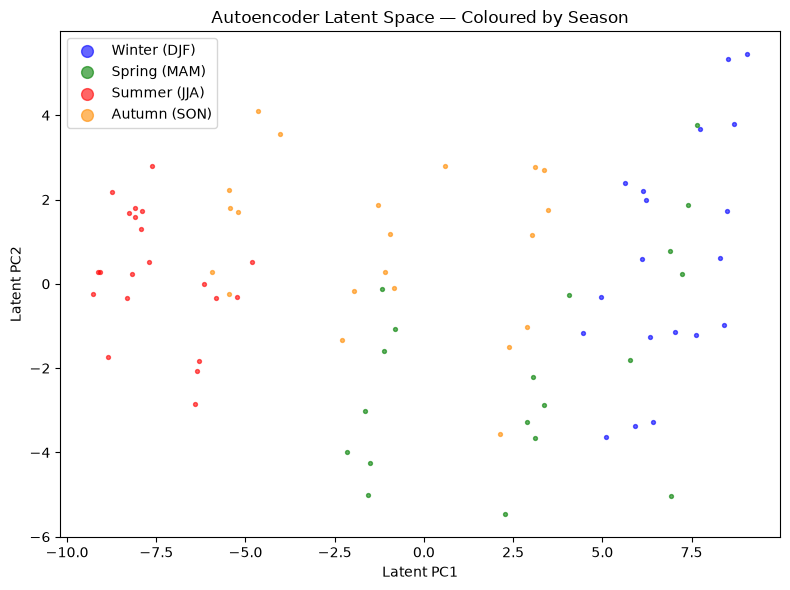

In [ ]:
model.eval()
latent_codes = []
with torch.no_grad():
    for batch in test_loader:
        z = model.encode(batch.to(DEVICE)).cpu().numpy()
        latent_codes.append(z)
latent_codes = np.concatenate(latent_codes, axis=0)  # (n_test, LATENT_DIM)

# Project to 2-D for visualisation
pca_vis = PCA(n_components=2).fit_transform(latent_codes)

# Colour by month
test_times = times[n_train + n_val:]
test_months = [np.datetime64(t, 'M').astype('datetime64[M]').astype(int) % 12 + 1
               for t in test_times[:n_test]]

seasons = {
    'Winter (DJF)': [12, 1, 2],
    'Spring (MAM)': [3, 4, 5],
    'Summer (JJA)': [6, 7, 8],
    'Autumn (SON)': [9, 10, 11],
}
season_colors = {'Winter (DJF)': 'blue', 'Spring (MAM)': 'green',
                 'Summer (JJA)': 'red',     'Autumn (SON)': 'darkorange'}

plt.figure(figsize=(8, 6))
for season, months in seasons.items():
    mask = np.isin(test_months, months)
    plt.scatter(pca_vis[mask, 0], pca_vis[mask, 1],
                c=season_colors[season], label=season, s=8, alpha=0.6)

plt.xlabel('Latent PC1'); plt.ylabel('Latent PC2')
plt.title('Autoencoder Latent Space — Coloured by Season')
plt.legend(markerscale=3)
plt.tight_layout()
plt.savefig('latent_space.png', dpi=100)
plt.show()
# Good sign: winter and summer cluster apart — the model has learned seasonality

---
## 11. Summary Results Table

In [27]:
import pandas as pd

rows = []
for ld in LATENT_DIMS_TO_TRY:
    row = next(r for r in comparison if r['latent_dim'] == ld)
    rows.append({
        'Latent dim':  ld,
        'Compression': f'{H*W/ld:.0f}×',
        'Clim RMSE':   f"{row['Clim_RMSE']:.5f}",
        'PCA RMSE':    f"{row['PCA_RMSE']:.5f}",
        'AE RMSE':     f"{row['AE_RMSE']:.5f}",
        'AE vs PCA':   '✓ better' if row['AE_RMSE'] < row['PCA_RMSE'] else '✗ worse',
        'AE vs Clim':  f"{100*(1 - row['AE_RMSE']/row['Clim_RMSE']):.1f}% reduction",
    })

df = pd.DataFrame(rows)
print(df.to_string(index=False))

 Latent dim Compression Clim RMSE PCA RMSE AE RMSE AE vs PCA      AE vs Clim
          8        128×   1.01759  0.19433 0.24460   ✗ worse 76.0% reduction
         16         64×   1.01759  0.10008 0.21392   ✗ worse 79.0% reduction
         32         32×   1.01759  0.04436 0.18378   ✗ worse 81.9% reduction
         64         16×   1.01759  0.02032 0.17002   ✗ worse 83.3% reduction
